# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Demo Notebook: Volume Visualization — Voxels, Slices, Isosurfaces and Volume Rendering

topics:

1. Volume Visualization Fundamentals: Why One 2-D Projection Is Not Enough
2. Volumetric Data: How Many Values Is a Volume?
3. Voxels: Pixels With Depth (and Physical Size)
4. 3-D Grids and Resolution Trade-offs
5. Volume Slicing (and What Lies Between Slices)
6. Orthogonal Slices and Multiplanar Reconstruction (MPR), incl. an Oblique Plane
7. Medical Display: Window / Level on CT Slices
8. Isosurface Visualization
9. Isosurface Extraction and Threshold Sensitivity
10. Direct Volume Rendering vs. Surface Rendering
11. Ray Casting: Following One Ray
12. Transfer Functions: Opacity and Colour Mapping
13. Volume Compositing (Front-to-Back)
14. Same Volume, Different Transfer Functions
15. Volume Rendering Challenges: Occlusion, Overlap, Cost
16. Segmentation and Anatomical Visualization
17. Simulation Data Visualization: A 3-D Thermal Simulation

**Dataset:** `unit3_ppt3_head_ct_phantom.csv` — a synthetic **head CT phantom** on a 64 × 64 × 48 voxel grid (196,608 voxels; voxel size
3 × 3 × 4 mm). Each row is one voxel: `x, y, z`, an `intensity_hu` value in Hounsfield-like units (air ≈ −1000,
CSF ≈ 10, brain ≈ 35, contrast-enhanced tumour ≈ 70, bone ≈ 700–900) including noise and **partial-volume
blurring** at tissue boundaries, and a ground-truth `label` (0 air, 1 scalp, 2 bone, 3 brain, 4 CSF/ventricles,
5 tumour) used only to *evaluate* our visualizations and segmentations. Synthetic so it is shareable — but it
behaves like a real CT, including the overlapping intensity ranges that make volume rendering hard.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"Volume shape (z, y, x) = {vol.shape} -> {vol.size:,} voxels; voxel = {SPACING} mm = {VOXEL_MM3:.0f} mm^3")
print(f"Physical extent: {NX*SPACING[2]:.0f} x {NY*SPACING[1]:.0f} x {NZ*SPACING[0]:.0f} mm")
ct.groupby("label").intensity_hu.describe()[["count", "mean", "min", "max"]].round(0)

Volume shape (z, y, x) = (48, 64, 64) -> 196,608 voxels; voxel = (4.0, 3.0, 3.0) mm = 36 mm^3
Physical extent: 192 x 192 x 192 mm


,count,mean,min,max
label,,,,
0,125320.0,-981.0,-1021.0,-549.0
1,11952.0,-9.0,-403.0,417.0
2,18472.0,734.0,441.0,978.0
3,39168.0,69.0,22.0,442.0
4,1232.0,12.0,4.0,30.0
5,464.0,66.0,49.0,77.0


## 1. Volume Visualization Fundamentals: Why One 2-D Projection Is Not Enough  *(Slides 4–5)*

**What:** Volumetric data V(x, y, z) → s carries information **through depth**. A single 2-D projection collapses
depth, so structures behind other structures are hidden. Pipeline: *Volumetric data → Visualization method →
2-D display → Interpretation.*

**Why:** Below, an X-ray-like average projection (every voxel along each ray averaged), a maximum-intensity
projection (MIP), and a single slice through the same head. The tumour that is obvious in the slice practically
disappears in both projections — the skull dominates every ray.

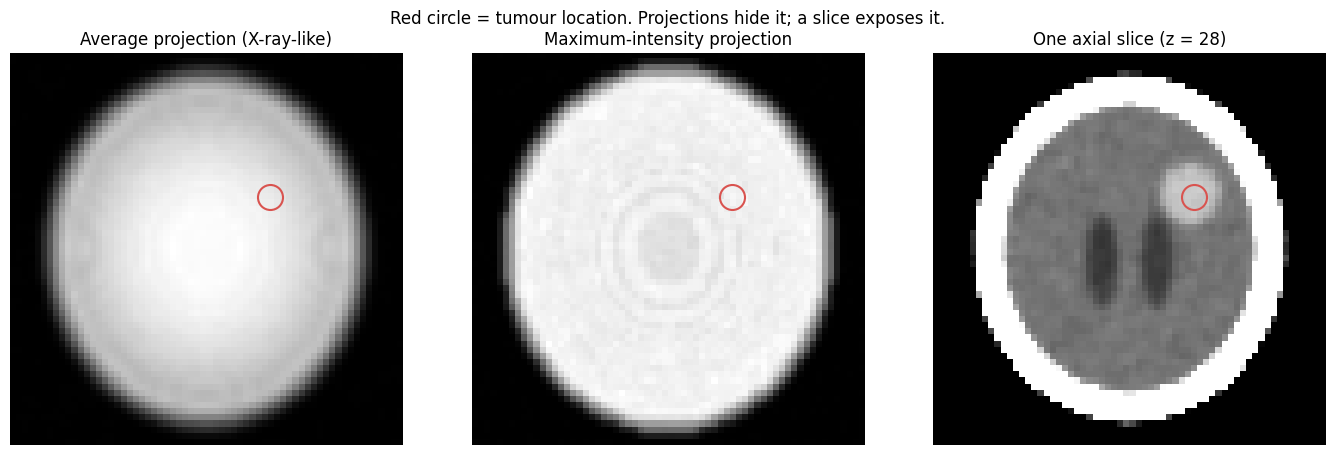

In [2]:
tz, ty, tx = np.round(np.argwhere(labels == 5).mean(axis=0)).astype(int)    # tumour centre, for reference
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(vol.mean(axis=0), cmap="gray", origin="lower"); axes[0].set_title("Average projection (X-ray-like)")
axes[1].imshow(vol.max(axis=0), cmap="gray", origin="lower"); axes[1].set_title("Maximum-intensity projection")
axes[2].imshow(np.clip(vol[tz], -20, 100), cmap="gray", origin="lower"); axes[2].set_title(f"One axial slice (z = {tz})")
for ax in axes: ax.plot(tx, ty, "o", mfc="none", mec="#D9534F", ms=18, mew=1.5); ax.axis("off")
plt.suptitle("Red circle = tumour location. Projections hide it; a slice exposes it.")
plt.tight_layout(); plt.show()

## 2. Volumetric Data: How Many Values Is a Volume?  *(Slides 6–7, 12)*

**What:** A regular volume of Nx × Ny × Nz samples holds **Nx·Ny·Nz** values — millions even for a single scan.
256 × 256 × 128 = 8,388,608; 512 × 512 × 300 = 78,643,200.

**Why:** Below, the slide numericals plus storage at 16 bits per voxel (the usual CT format) — the reason volume
visualization is a performance problem as well as a perception problem.

In [3]:
for nx, ny, nz in [(64, 64, 48), (256, 256, 128), (512, 512, 300)]:
    n = nx * ny * nz
    print(f"{nx} x {ny} x {nz} = {n:>11,} voxels -> {n*2/1024**2:7.1f} MB at 16 bits/voxel")

64 x 64 x 48 =     196,608 voxels ->     0.4 MB at 16 bits/voxel
256 x 256 x 128 =   8,388,608 voxels ->    16.0 MB at 16 bits/voxel
512 x 512 x 300 =  78,643,200 voxels ->   150.0 MB at 16 bits/voxel


## 3. Voxels: Pixels With Depth (and Physical Size)  *(Slides 8–10)*

**What:** A voxel (volume + pixel) is a discrete 3-D sample/cell at (x, y, z), with physical size Δx × Δy × Δz.
A voxel is **not just a cube on screen** — it is a sample of the underlying data; its physical dimensions set the
spatial resolution, and voxels are often **anisotropic** (here 3 × 3 × 4 mm).

**Why:** Below, a sagittal slice displayed twice: treating voxels as square pixels (wrong — the head is squashed
by 25%) vs. using the true voxel aspect ratio. Forgetting physical voxel size is a classic volume-vis bug.

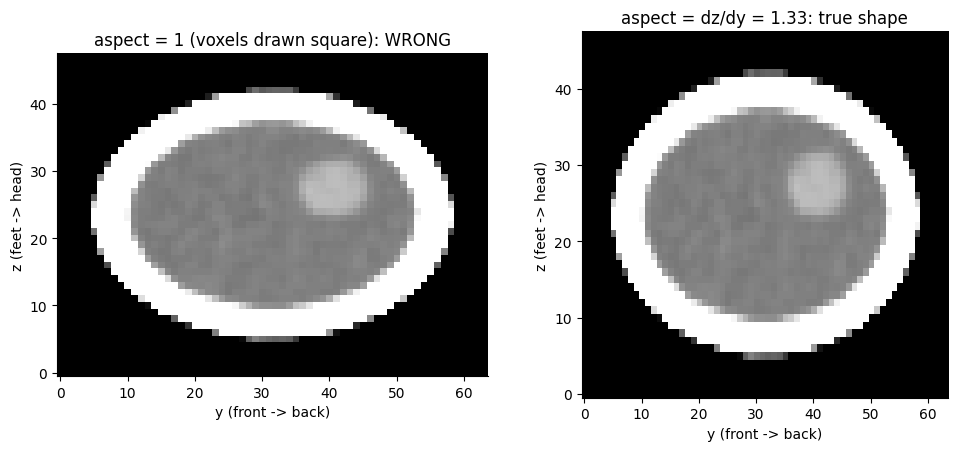

One voxel = 3.0 x 3.0 x 4.0 mm = 36 mm^3 = 0.036 mL


In [4]:
sag = np.clip(vol[:, :, tx], -50, 120)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
axes[0].imshow(sag, cmap="gray", origin="lower", aspect=1.0); axes[0].set_title("aspect = 1 (voxels drawn square): WRONG")
axes[1].imshow(sag, cmap="gray", origin="lower", aspect=ASPECT); axes[1].set_title(f"aspect = dz/dy = {ASPECT:.2f}: true shape")
for ax in axes: ax.set_xlabel("y (front -> back)"); ax.set_ylabel("z (feet -> head)")
plt.tight_layout(); plt.show()
print(f"One voxel = {SPACING[2]} x {SPACING[1]} x {SPACING[0]} mm = {VOXEL_MM3:.0f} mm^3 = {VOXEL_MM3/1000:.3f} mL")

## 4. 3-D Grids and Resolution Trade-offs  *(Slides 11–12)*

**What:** A continuous field becomes computable when sampled on a 3-D grid Nx × Ny × Nz. Higher resolution gives
more detail but multiplies storage, processing and rendering workload (halving the voxel size in all three axes
= 8× the voxels).

**Why:** Below, the axial slice through the tumour at full resolution, ½ and ¼ resolution. At ¼ resolution the
voxel count drops 64× — and the 30 mm tumour is reduced to a few blurry voxels.

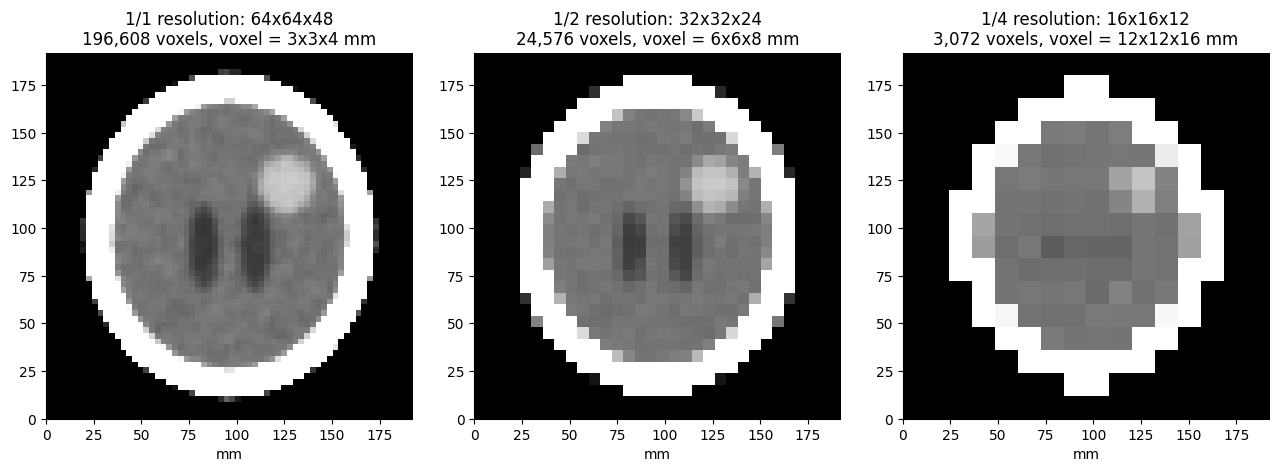

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, k in zip(axes, [1, 2, 4]):
    v = ndimage.zoom(vol.astype(float), 1 / k, order=1)
    ax.imshow(np.clip(v[int(tz / k)], -20, 100), cmap="gray", origin="lower", extent=[0, NX * 3, 0, NY * 3])
    ax.set_title(f"1/{k} resolution: {v.shape[2]}x{v.shape[1]}x{v.shape[0]}\n{v.size:,} voxels, voxel = {3*k}x{3*k}x{4*k} mm")
    ax.set_xlabel("mm")
plt.tight_layout(); plt.show()

## 5. Volume Slicing (and What Lies Between Slices)  *(Slides 13–14)*

**What:** A slice extracts V(x, y, z₀) — 3-D → 2-D while keeping the values in that plane. It exposes internal
regions, avoids occlusion and is cheap. **Limitation:** a single slice shows one plane; structures can lie
*between* slices, outside the plane, or at an orientation the plane misses. *Slicing does not reconstruct the 3-D
structure.*

**Why:** Below, every 4th axial slice (a typical "slice stack" review). The tumour appears in only a few panels;
a coarser stack could skip it entirely.

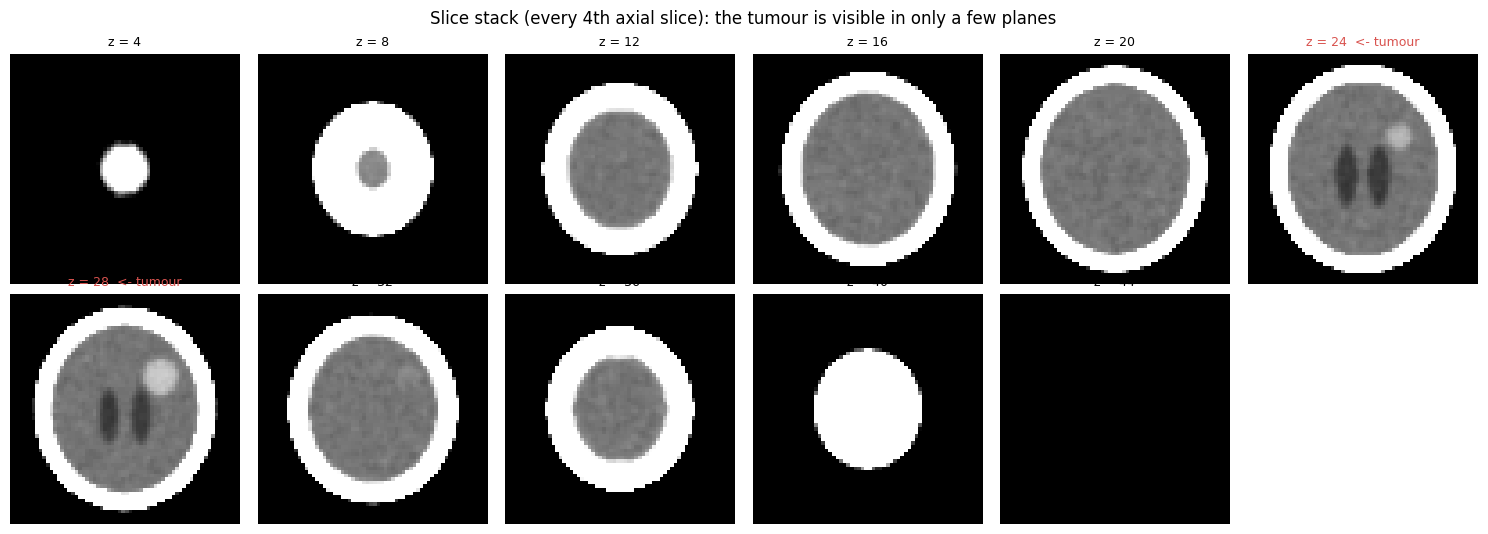

Tumour spans axial slices z = 24..31 (8 of 48 slices)


In [6]:
zs = np.arange(4, NZ - 2, 4)
fig, axes = plt.subplots(2, len(zs) // 2 + len(zs) % 2, figsize=(15, 5.4))
for ax, z in zip(axes.flat, zs):
    ax.imshow(np.clip(vol[z], -20, 100), cmap="gray", origin="lower")
    has_tumour = (labels[z] == 5).any()
    ax.set_title(f"z = {z}" + ("  <- tumour" if has_tumour else ""), fontsize=9, color="#D9534F" if has_tumour else "black")
    ax.axis("off")
for ax in axes.flat[len(zs):]: ax.axis("off")
plt.suptitle("Slice stack (every 4th axial slice): the tumour is visible in only a few planes")
plt.tight_layout(); plt.show()
z_with = np.unique(np.nonzero(labels == 5)[0])
print(f"Tumour spans axial slices z = {z_with.min()}..{z_with.max()} ({len(z_with)} of {NZ} slices)")

## 6. Orthogonal Slices and Multiplanar Reconstruction (MPR)  *(Slides 15–17)*

**What:** Orthogonal slices are perpendicular to the principal axes: **axial** (z = z₀), **coronal** (y = y₀),
**sagittal** (x = x₀). **MPR** shows several planes of the *same* volume together, with linked cross-hairs, so a
structure found in one plane can be located in the others. **Oblique** planes handle structures that don't align
with the axes.

**Why:** Below, a 3-plane MPR centred on the tumour (cross-hairs link the views), plus an oblique plane tilted 45°
— computed by sampling the volume along a rotated plane with trilinear interpolation.

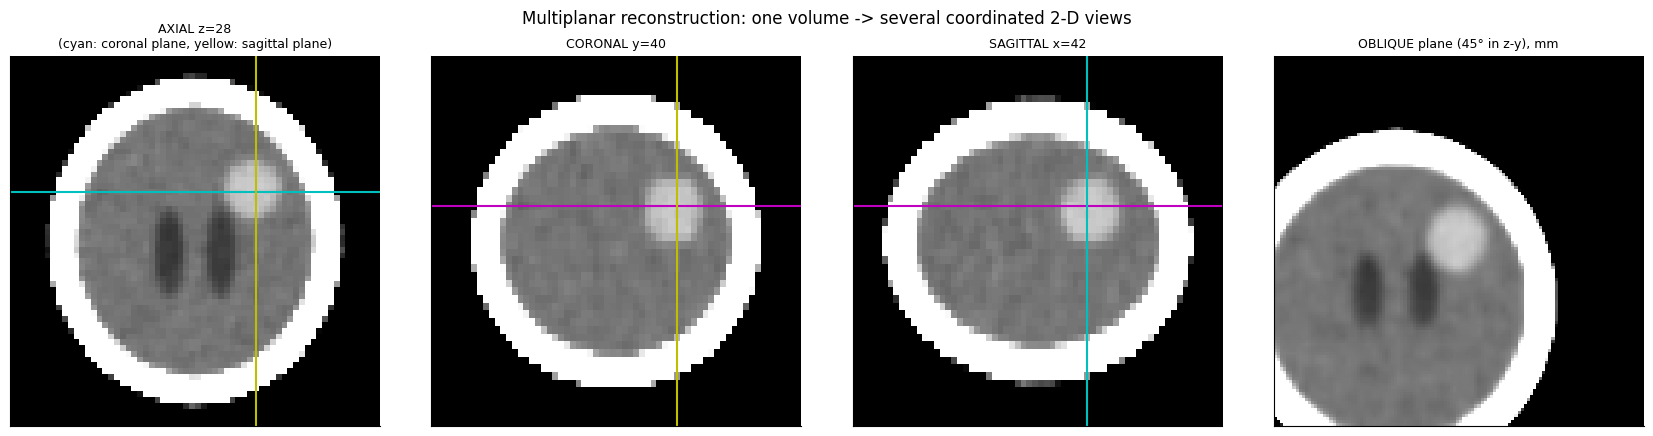

In [7]:
from scipy.ndimage import map_coordinates
win = lambda a: np.clip(a, -20, 100)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
axes[0].imshow(win(vol[tz]), cmap="gray", origin="lower"); axes[0].axhline(ty, color="c"); axes[0].axvline(tx, color="y")
axes[0].set_title(f"AXIAL z={tz}\n(cyan: coronal plane, yellow: sagittal plane)", fontsize=9)
axes[1].imshow(win(vol[:, ty, :]), cmap="gray", origin="lower", aspect=ASPECT); axes[1].axhline(tz, color="m"); axes[1].axvline(tx, color="y")
axes[1].set_title(f"CORONAL y={ty}", fontsize=9)
axes[2].imshow(win(vol[:, :, tx]), cmap="gray", origin="lower", aspect=ASPECT); axes[2].axhline(tz, color="m"); axes[2].axvline(ty, color="c")
axes[2].set_title(f"SAGITTAL x={tx}", fontsize=9)

# oblique plane through the tumour centre, tilted 45 degrees about the x-axis (physical coordinates, mm)
u_dir = np.array([0, 0, 1.0])                                  # in-plane axis 1: along x
v_dir = np.array([1, 1, 0.0]) / np.sqrt(2)                     # in-plane axis 2: diagonal in (z, y)
s_mm = np.arange(-90, 90, 1.5)
S1, S2 = np.meshgrid(s_mm, s_mm)
centre_mm = np.array([tz, ty, tx]) * SPACING
pts_mm = centre_mm + S1[..., None] * u_dir + S2[..., None] * v_dir
oblique = map_coordinates(vol.astype(float), (pts_mm / SPACING).transpose(2, 0, 1), order=1, cval=-1000)
axes[3].imshow(win(oblique), cmap="gray", origin="lower", extent=[s_mm[0], s_mm[-1], s_mm[0], s_mm[-1]])
axes[3].set_title("OBLIQUE plane (45° in z-y), mm", fontsize=9)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Multiplanar reconstruction: one volume -> several coordinated 2-D views")
plt.tight_layout(); plt.show()

## 7. Medical Display: Window / Level on CT Slices  *(Slide 30)*

**What:** CT intensities span ≈ 3,000 HU but a display shows ~256 grey levels (and the eye far fewer). Radiologists
choose a **window** (width W, centre/level L) — a transfer function for 2-D slices: values below L − W/2 → black,
above L + W/2 → white. CT is strong for bone/density; MRI gives stronger soft-tissue contrast.

**Why:** Below, the same slice with the full range, a **brain window** (W = 80, L = 40) and a **bone window**
(W = 2000, L = 500). Each window is a different answer to "which structures should be distinguishable?"

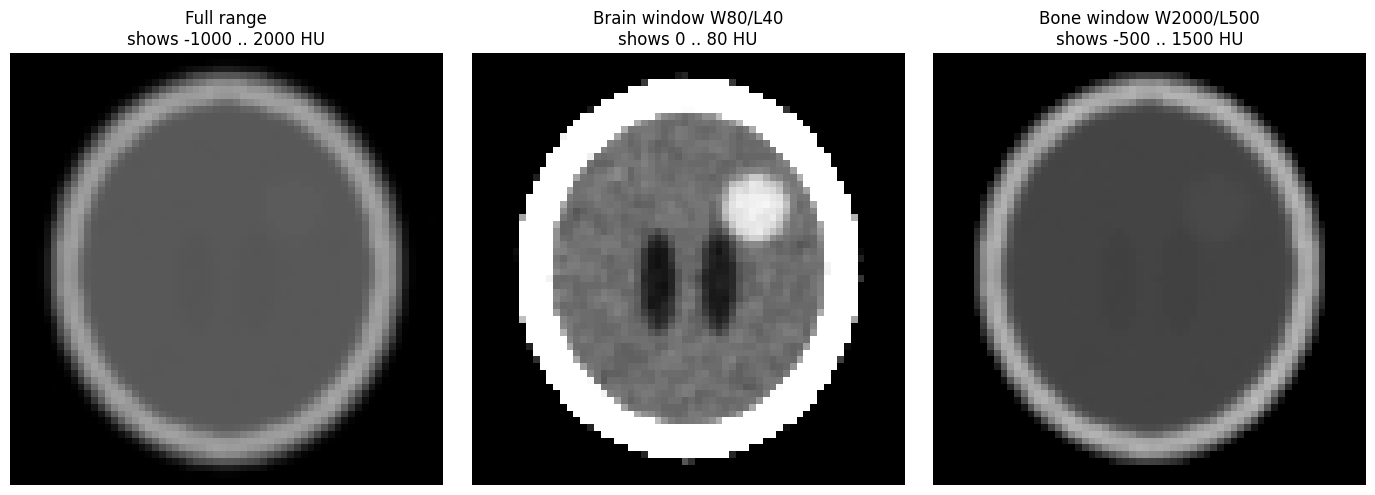

In [8]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (W, L, name) in zip(axes, [(3000, 500, "Full range"), (80, 40, "Brain window W80/L40"), (2000, 500, "Bone window W2000/L500")]):
    ax.imshow(window(vol[tz], W, L), cmap="gray", origin="lower", vmin=0, vmax=1)
    ax.set_title(f"{name}\nshows {L - W/2:.0f} .. {L + W/2:.0f} HU"); ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Isosurface Visualization  *(Slide 18)*

**What:** An isosurface connects all locations where **V(x, y, z) = c** (the 3-D analogue of an isocontour
S(x, y) = c). It shows the shape and extent of the selected level as a 3-D surface rather than a 2-D section.

**Why:** Below we extract two isosurfaces — the outer skull surface (c = 300 HU) and the tumour boundary
(c = 50 HU) — and show them together with a cut-away so the inner surface is visible. Extraction method: for each
direction from a structure's centre we march along a ray and find where the value crosses c (the same
"where does the field cross c?" test Marching Cubes performs on every voxel edge; this shortcut works because both
structures are star-shaped around their centre).

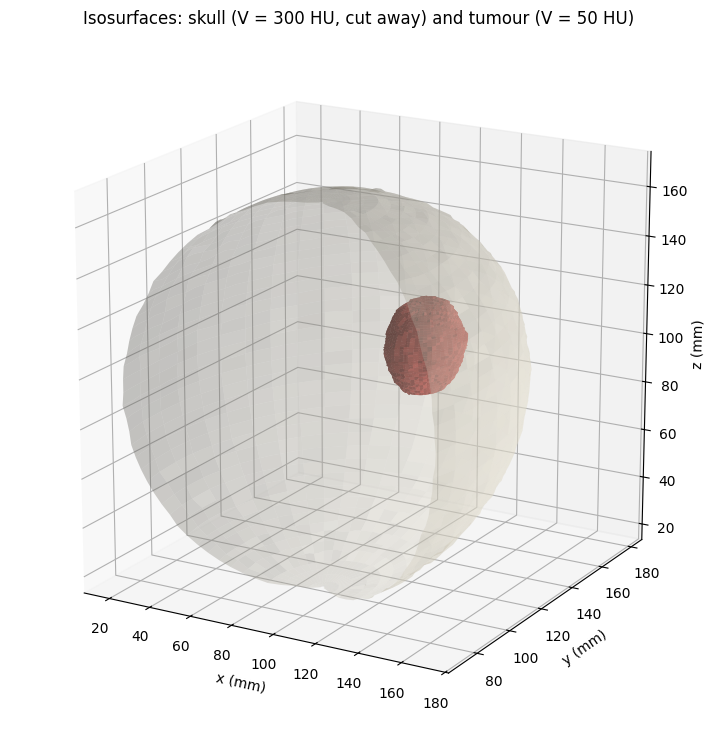

In [9]:
def star_isosurface(centre_vox, c, r_max_mm, outermost, n_theta=48, n_phi=96):
    th = np.linspace(0.01, np.pi - 0.01, n_theta); ph = np.linspace(0, 2 * np.pi, n_phi)
    TH, PH = np.meshgrid(th, ph, indexing="ij")
    dirs = np.stack([np.cos(TH), np.sin(TH) * np.sin(PH), np.sin(TH) * np.cos(PH)], -1)    # (z, y, x) unit vectors
    r = np.arange(0, r_max_mm, 0.75)
    pts = np.array(centre_vox) * SPACING + r[:, None, None, None] * dirs[None]              # mm
    vals = map_coordinates(vol.astype(float), (pts / SPACING).transpose(3, 0, 1, 2), order=1, cval=-1000)
    above = vals > c
    if outermost:   idx = r.size - 1 - np.argmax(above[::-1], axis=0)                       # last crossing from inside
    else:           idx = np.argmax(~above, axis=0)                                         # first time we leave the region
    R = r[idx]
    xyz = np.array(centre_vox) * SPACING + R[..., None] * dirs
    return xyz[..., 2], xyz[..., 1], xyz[..., 0], PH

head_c = (NZ / 2, NY / 2, NX / 2)
sx, sy, sz, ph = star_isosurface(head_c, 300, 120, outermost=True)
cut = (ph > np.radians(200)) & (ph < np.radians(340))                                      # cut-away wedge
sx, sy, sz = [np.where(cut, np.nan, a) for a in (sx, sy, sz)]
ux, uy, uz, _ = star_isosurface((tz, ty, tx), 50, 40, outermost=False)

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(sx, sy, sz, color="#e8e2d0", alpha=0.35, linewidth=0)
ax.plot_surface(ux, uy, uz, color="#D9534F", linewidth=0)
ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)"); ax.set_zlabel("z (mm)"); ax.view_init(18, -60)
ax.set_box_aspect((NX * 3, NY * 3, NZ * 4))
ax.set_title("Isosurfaces: skull (V = 300 HU, cut away) and tumour (V = 50 HU)")
plt.tight_layout(); plt.show()

## 9. Isosurface Extraction and Threshold Sensitivity  *(Slides 19–20)*

**What:** Isosurface extraction: *Scalar volume → threshold c → surface extraction (e.g. Marching Cubes) → 3-D
triangle mesh*. Explicit geometry supports lighting, rotation and measurement — **but the chosen c strongly
determines the geometry**; different c values give different surfaces from the same volume.

**Why:** Below, the tumour region grown from its centre at six thresholds. The "tumour volume" a surgeon would
read off the surface changes by a factor of three depending on c. (The ground-truth label lets us score each
threshold with the Dice overlap.)

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


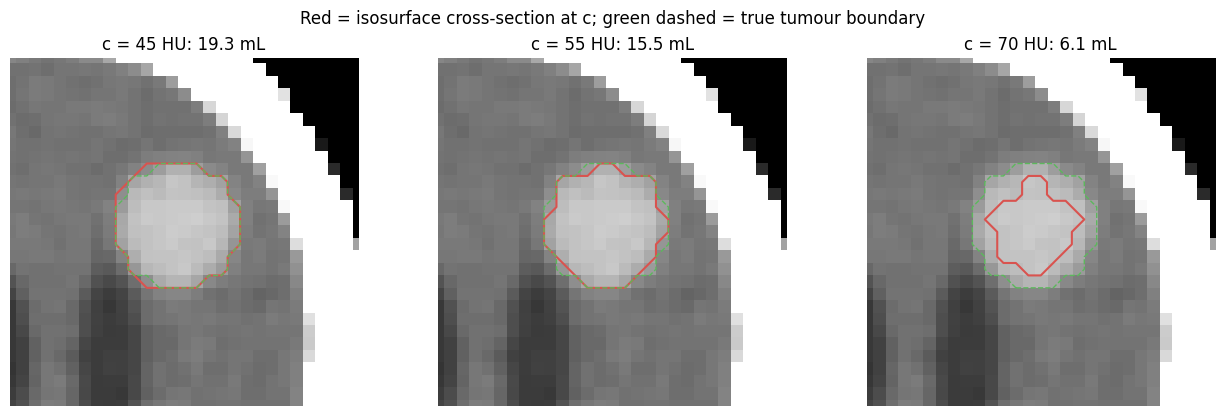

In [10]:
truth = labels == 5
rows = []
for c in [45, 50, 55, 60, 65, 70]:
    comp, _ = ndimage.label(vol > c)
    region = comp == comp[tz, ty, tx]
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold_hu": c, "voxels": int(region.sum()), "volume_ml": region.sum() * VOXEL_MM3 / 1000, "dice_vs_truth": dice})
sens = pd.DataFrame(rows).round(3); display(sens)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, c in zip(axes, [45, 55, 70]):
    comp, _ = ndimage.label(vol > c); region = comp == comp[tz, ty, tx]
    ax.imshow(np.clip(vol[tz], -20, 100), cmap="gray", origin="lower")
    ax.contour(region[tz], levels=[0.5], colors="#D9534F", linewidths=1.5)
    ax.contour(truth[tz], levels=[0.5], colors="#5cb85c", linewidths=1, linestyles="--")
    ax.set_xlim(tx - 14, tx + 14); ax.set_ylim(ty - 14, ty + 14); ax.axis("off")
    ax.set_title(f"c = {c} HU: {region.sum()*VOXEL_MM3/1000:.1f} mL")
plt.suptitle("Red = isosurface cross-section at c; green dashed = true tumour boundary")
plt.tight_layout(); plt.show()

## 10. Direct Volume Rendering vs. Surface Rendering  *(Slide 21)*

**What:** Isosurface rendering: *Volume → surface extraction → geometry → image* (one level, explicit surface).
**Direct volume rendering (DVR):** *Volume → colour + opacity → image* — every voxel can contribute, semi-
transparent regions reveal internal structure, and no single threshold is required.

**Why:** Below, the same head as (a) a binary "bone" surface view at c = 300 (a pure isosurface decision: each ray
stops at the first bone voxel), and (b) a direct volume rendering in which skin, bone, brain and tumour all
contribute with partial opacity.

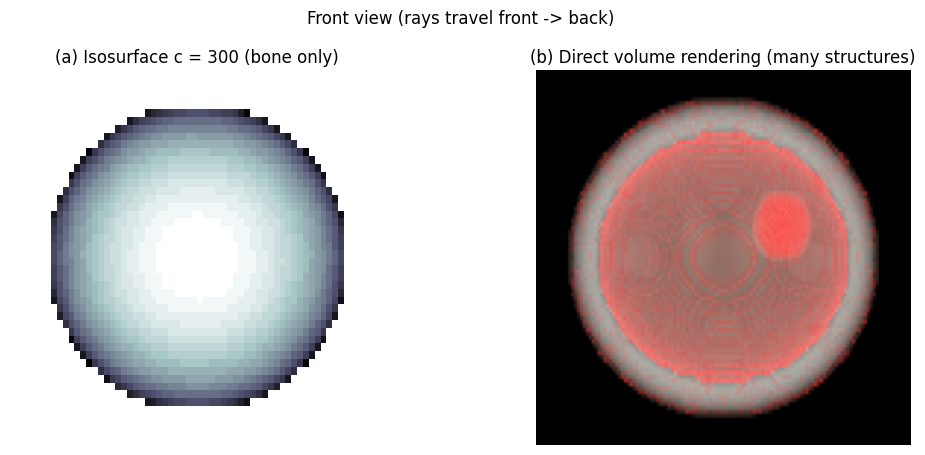

In [11]:
# (a) surface-style: first voxel along each ray above c, shaded by depth
bone = vol > 300
first = np.argmax(bone, axis=1).astype(float); first[~bone.any(axis=1)] = np.nan
surface_img = 1 - first / NY

# (b) direct volume rendering
tf_dvr = make_tf([(-1000, (0, 0, 0), 0), (-200, (0, 0, 0), 0), (-50, (0.9, 0.7, 0.6), 0.02),
                  (30, (0.95, 0.75, 0.65), 0.004), (45, (0.95, 0.75, 0.65), 0.004),
                  (60, (1, 0.1, 0.1), 0.15), (80, (1, 0.1, 0.1), 0.15), (100, (0.9, 0.9, 0.9), 0.0),
                  (300, (1, 1, 0.95), 0.015), (1500, (1, 1, 1), 0.025)])
C, A = render(vol, tf_dvr, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].imshow(surface_img, cmap="bone", origin="lower", aspect=ASPECT); axes[0].set_title("(a) Isosurface c = 300 (bone only)")
axes[1].imshow(np.clip(C, 0, 1), origin="lower", aspect=ASPECT); axes[1].set_title("(b) Direct volume rendering (many structures)")
for ax in axes: ax.axis("off")
plt.suptitle("Front view (rays travel front -> back)")
plt.tight_layout(); plt.show()

## 11. Ray Casting: Following One Ray  *(Slides 22–23)*

**What:** For each pixel a ray r(t) = o + t·d enters the volume and is **sampled at successive positions**; each
sample's scalar value is mapped to colour and opacity and the contributions are accumulated. *The final pixel does
not correspond to one voxel — it is the accumulated contribution of many samples.*

**Why:** Below we follow the single ray that passes through the tumour centre: the scalar value at each sample, the
opacity the transfer function assigns, and how much each sample actually contributes to the final pixel (its
opacity times the transparency still remaining in front of it).

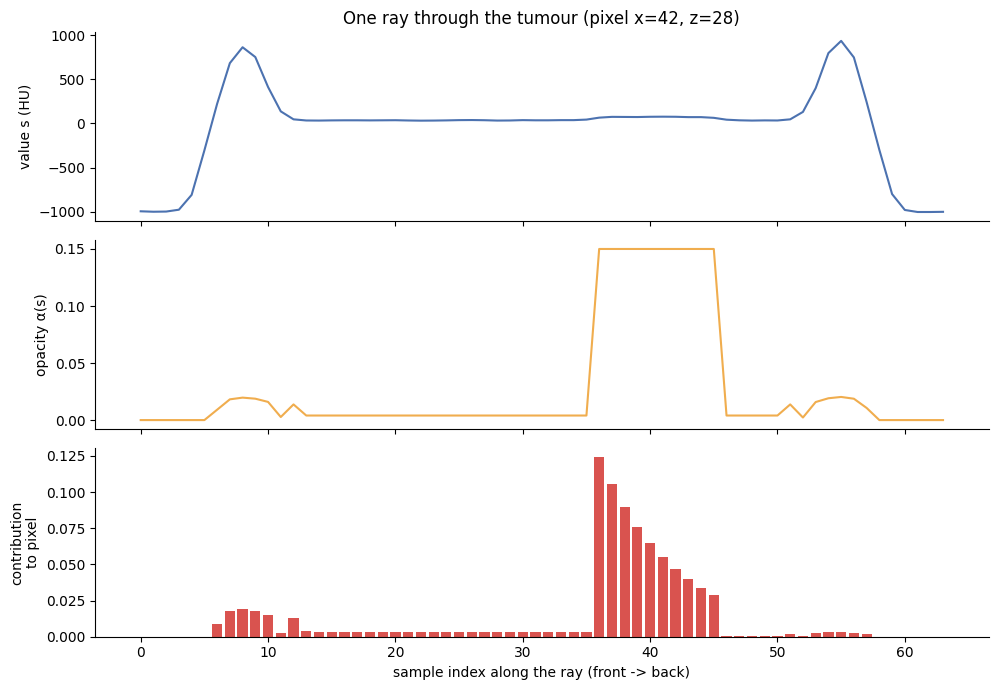

Samples on this ray: 64;  samples contributing >1% of the pixel: 15;  final accumulated opacity = 0.856


In [12]:
ray = vol[tz, :, tx].astype(float)                     # all samples along y for this pixel
_, a = tf_dvr(ray)
remaining = np.cumprod(np.r_[1, 1 - a[:-1]])           # transparency left in front of each sample
weight = remaining * a

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(ray, color="#4C72B0"); axes[0].set_ylabel("value s (HU)"); axes[0].set_title(f"One ray through the tumour (pixel x={tx}, z={tz})")
axes[1].plot(a, color="#f0ad4e"); axes[1].set_ylabel("opacity α(s)")
axes[2].bar(np.arange(NY), weight, color="#D9534F"); axes[2].set_ylabel("contribution\nto pixel"); axes[2].set_xlabel("sample index along the ray (front -> back)")
plt.tight_layout(); plt.show()
print(f"Samples on this ray: {NY};  samples contributing >1% of the pixel: {(weight > 0.01).sum()};  "
      f"final accumulated opacity = {1 - np.prod(1 - a):.3f}")

## 12. Transfer Functions: Opacity and Colour Mapping  *(Slides 24–26)*

**What:** A transfer function **T(s) → (C, α)** maps each scalar value to a colour and an opacity
(α = 0 transparent, α = 1 opaque). **Opacity** decides *visibility* (reveal or suppress); **colour** decides
*differentiation* (which material is which). Give the two channels distinct analytical roles.

**Why:** Below, the DVR transfer function from Section 10 drawn on top of the volume's intensity histogram
(log scale): you can see which tissue populations each part of the TF "selects".

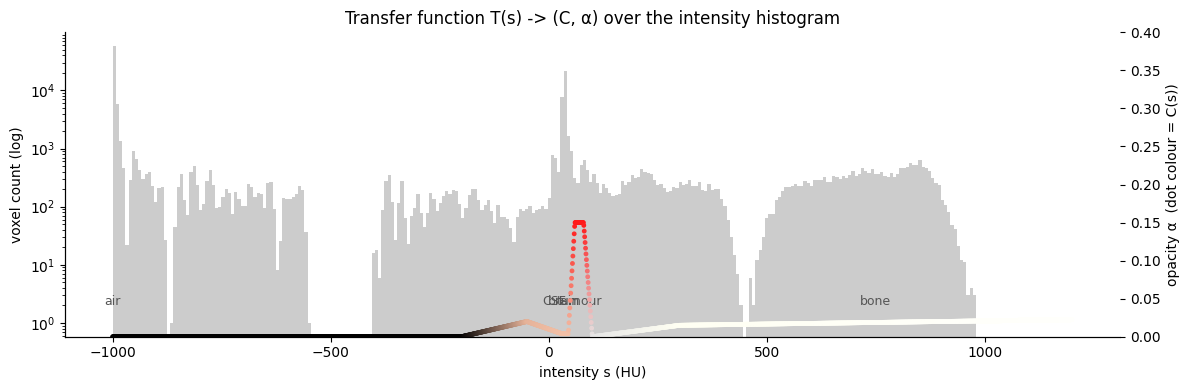

In [13]:
s = np.linspace(-1000, 1200, 2200)
c, a = tf_dvr(s)
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(vol.ravel(), bins=300, range=(-1000, 1200), color="#cccccc", log=True)
ax.set_ylabel("voxel count (log)"); ax.set_xlabel("intensity s (HU)")
ax2 = ax.twinx()
ax2.scatter(s, a, c=np.clip(c, 0, 1), s=6); ax2.set_ylabel("opacity α  (dot colour = C(s))"); ax2.set_ylim(0, 0.4)
for hu, name in [(-1000, "air"), (12, "CSF"), (35, "brain"), (70, "tumour"), (750, "bone")]:
    ax.annotate(name, (hu, 2), fontsize=9, ha="center", color="#555555")
ax.set_title("Transfer function T(s) -> (C, α) over the intensity histogram")
plt.tight_layout(); plt.show()

## 13. Volume Compositing (Front-to-Back)  *(Slide 27)*

**What:** Front-to-back compositing accumulates colour and opacity along a ray:
**C_acc ← C_acc + (1 − α_acc)·α_i·C_i** and **α_acc ← α_acc + (1 − α_acc)·α_i**. Opaque samples contribute strongly,
transparent ones little; as α_acc → 1, later samples barely matter — which is what makes **early ray termination**
possible.

**Why:** A three-sample worked example by hand, then the early-termination saving on our whole rendering.

In [14]:
samples = [("red", np.array([1, 0, 0]), 0.3), ("green", np.array([0, 1, 0]), 0.5), ("blue", np.array([0, 0, 1]), 0.8)]
C_acc, A_acc = np.zeros(3), 0.0
for name, Ci, ai in samples:
    contrib = (1 - A_acc) * ai
    C_acc = C_acc + contrib * Ci; A_acc = A_acc + (1 - A_acc) * ai
    print(f"{name:>5}: alpha_i={ai}  contributes {contrib:.3f}  ->  C_acc={np.round(C_acc, 3)}, alpha_acc={A_acc:.3f}")

opaque_bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 1, 1), 0.6), (1500, (1, 1, 1), 0.9)])
v = np.moveaxis(vol, 1, 0)
print()
for name, tf in [("semi-transparent DVR TF", tf_dvr), ("opaque bone TF", opaque_bone_tf)]:
    A_run = np.zeros(v.shape[1:]); needed = np.zeros(v.shape[1:])
    for sample in v:
        needed += A_run < 0.95                          # this sample is still needed (pixel not yet ~opaque)
        A_run += (1 - A_run) * tf(sample)[1]
    print(f"Early ray termination at alpha_acc >= 0.95 with the {name}: skips {100 * (1 - needed.sum() / v.size):.1f}% of samples")
print("-> the more opaque the transfer function, the more work early termination saves.")

  red: alpha_i=0.3  contributes 0.300  ->  C_acc=[0.3 0.  0. ], alpha_acc=0.300
green: alpha_i=0.5  contributes 0.350  ->  C_acc=[0.3  0.35 0.  ], alpha_acc=0.650
 blue: alpha_i=0.8  contributes 0.280  ->  C_acc=[0.3  0.35 0.28], alpha_acc=0.930

Early ray termination at alpha_acc >= 0.95 with the semi-transparent DVR TF: skips 0.0% of samples
Early ray termination at alpha_acc >= 0.95 with the opaque bone TF: skips 38.2% of samples
-> the more opaque the transfer function, the more work early termination saves.


## 14. Same Volume, Different Transfer Functions  *(Slides 24–26)*

**What:** The transfer function *is* the visualization design. Changing it changes which structures are visible,
without changing the data.

**Why:** Below, four renderings of the identical volume: a **bone preset**, a **soft-tissue preset**, a
**tumour-hunting preset** (bone and brain almost transparent, tumour opaque red, ventricles blue), and a MIP for
comparison.

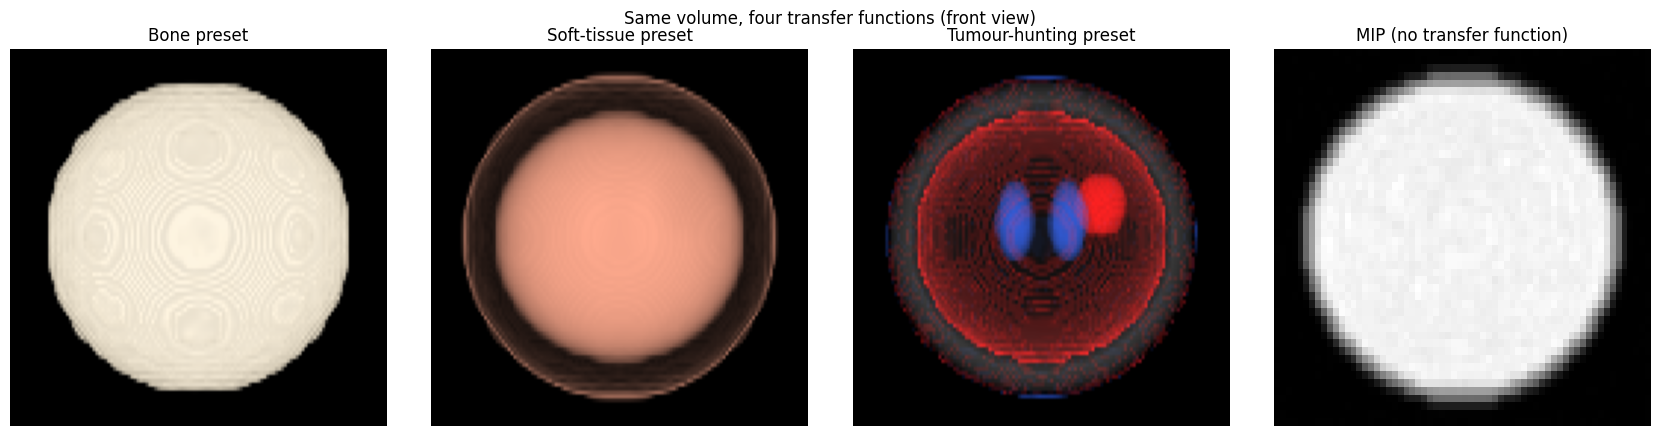

In [15]:
presets = {
    "Bone preset": make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)]),
    "Soft-tissue preset": make_tf([(-1000, (0, 0, 0), 0), (-300, (0, 0, 0), 0), (-50, (0.9, 0.6, 0.5), 0.05),
                                   (60, (0.9, 0.6, 0.5), 0.02), (200, (0, 0, 0), 0), (1500, (0, 0, 0), 0)]),
    "Tumour-hunting preset": make_tf([(-1000, (0, 0, 0), 0), (0, (0, 0, 0), 0), (5, (0.2, 0.4, 1), 0.04), (20, (0.2, 0.4, 1), 0.04),
                                      (28, (0, 0, 0), 0), (55, (0, 0, 0), 0), (62, (1, 0.1, 0.1), 0.12), (80, (1, 0.1, 0.1), 0.12),
                                      (95, (0, 0, 0), 0), (400, (1, 1, 1), 0.004), (1500, (1, 1, 1), 0.004)]),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, (name, tf) in zip(axes, presets.items()):
    C, _ = render(vol, tf, axis=1)
    ax.imshow(np.clip(C / max(C.max(), 1e-9), 0, 1), origin="lower", aspect=ASPECT); ax.set_title(name); ax.axis("off")
axes[3].imshow(vol.max(axis=1), cmap="gray", origin="lower", aspect=ASPECT); axes[3].set_title("MIP (no transfer function)"); axes[3].axis("off")
plt.suptitle("Same volume, four transfer functions (front view)")
plt.tight_layout(); plt.show()

## 15. Volume Rendering Challenges: Occlusion, Overlap, Cost  *(Slides 28–29)*

**What:**
1. **Occlusion** — near structures hide deeper ones.
2. **Transfer-function selection** — materials have *overlapping* scalar ranges, so a value does not identify a
   unique structure.
3. **Depth perception** — 3-D shown on 2-D needs cues (occlusion, shading, perspective, motion, stereo).
4. **Computational cost** — resolution ↑ ⇒ rendering workload ↑.
5. **Visual complexity** — show the relevant structure, not everything.

**Why:** Left: per-tissue intensity histograms — brain voxels next to bone are partial-volume blurred into the
tumour's 55–80 HU range, so *any* TF that shows the tumour also shows a thin shell under the skull (visible in
the tumour preset above). Right: ray-casting cost for common volume sizes.

Voxels in the tumour's 55-80 HU range: 1,414, of which truly tumour: 442 (31%)


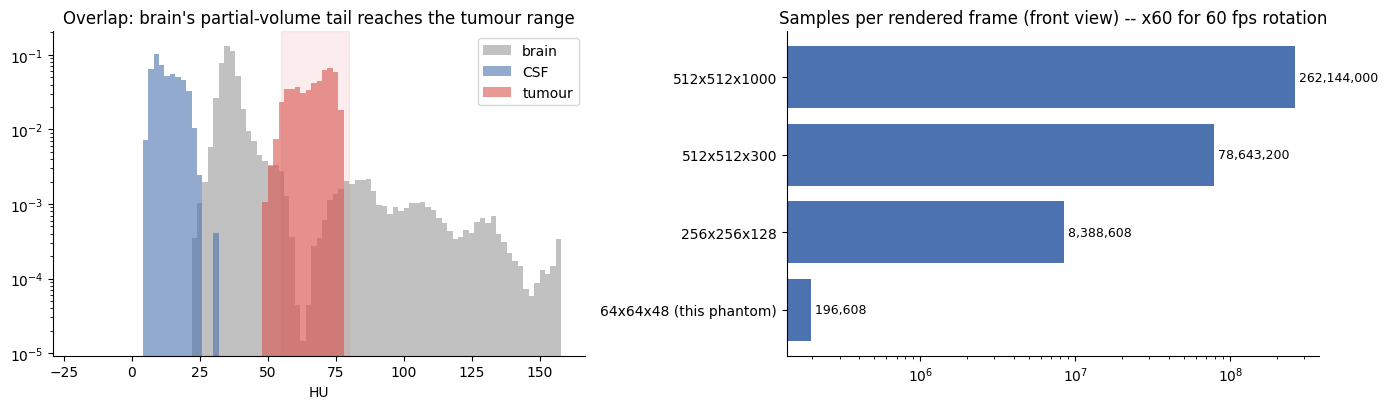

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for k, name, col in [(3, "brain", "#999999"), (4, "CSF", "#4C72B0"), (5, "tumour", "#D9534F")]:
    axes[0].hist(vol[labels == k], bins=np.arange(-20, 160, 2), alpha=0.6, density=True, label=name, color=col)
axes[0].axvspan(55, 80, color="#D9534F", alpha=0.1); axes[0].set_xlabel("HU"); axes[0].set_yscale("log")
axes[0].set_title("Overlap: brain's partial-volume tail reaches the tumour range"); axes[0].legend()
in_range = (vol >= 55) & (vol <= 80)
print(f"Voxels in the tumour's 55-80 HU range: {in_range.sum():,}, of which truly tumour: {(in_range & (labels == 5)).sum():,} "
      f"({100 * (in_range & (labels == 5)).sum() / in_range.sum():.0f}%)")

sizes = {"64x64x48 (this phantom)": (64, 64, 48), "256x256x128": (256, 256, 128), "512x512x300": (512, 512, 300), "512x512x1000": (512, 512, 1000)}
samples = {k: nx * nz * ny for k, (nx, ny, nz) in sizes.items()}          # one ray per pixel, one sample per voxel step
axes[1].barh(list(samples), list(samples.values()), color="#4C72B0"); axes[1].set_xscale("log")
for i, v in enumerate(samples.values()): axes[1].text(v, i, f" {v:,.0f}", va="center", fontsize=9)
axes[1].set_title("Samples per rendered frame (front view) -- x60 for 60 fps rotation")
plt.tight_layout(); plt.show()

## 16. Segmentation and Anatomical Visualization  *(Slides 31–32)*

**What:** Segmentation divides the volume into meaningful regions (bone, organs, vessels, tumour); each label is a
structure. Visualization then decides how regions are shown: colour overlays on slices, extracted surfaces, volume
rendering, or hybrids. *Segmentation creates the regions; visualization decides how they are presented.* It also
enables **quantitative measurement**.

**Why:** Below, a simple rule-based segmentation (thresholds + connected components + "inside the skull"), scored
against the ground truth with the Dice coefficient, shown as a colour overlay on the MPR slices and measured in mL.

,structure,voxels,volume_ml,true_ml,dice
0,bone,21691,780.9,665.0,0.920
1,CSF / ventricles,1138,41.0,44.4,0.960
2,tumour,464,16.7,16.7,0.994


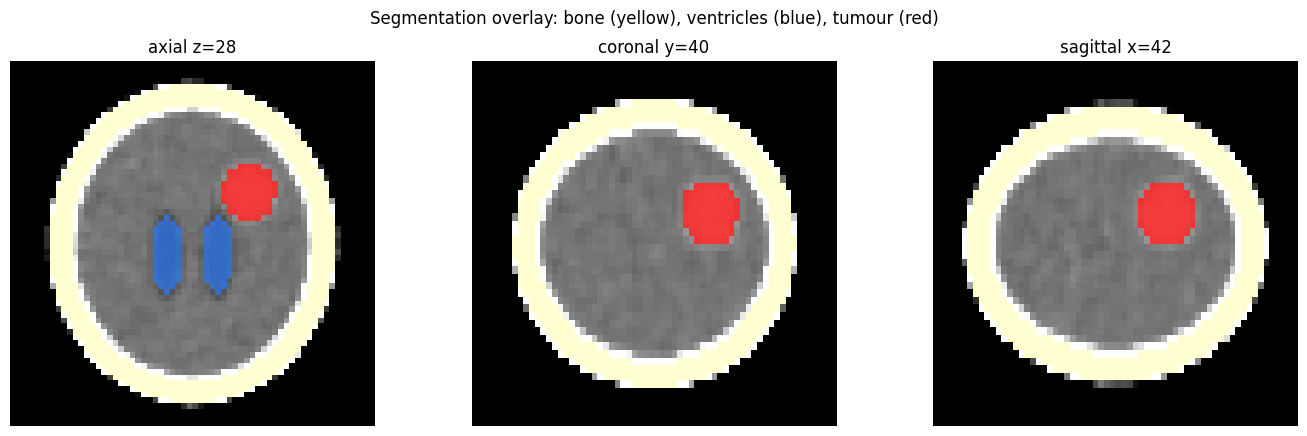

In [17]:
seg = np.zeros_like(labels)
bone_s = vol > 300
inside = ndimage.binary_fill_holes(bone_s) & ~bone_s
csf_s = inside & (vol < 22)
csf_s = ndimage.binary_opening(csf_s, iterations=1)
comp, _ = ndimage.label(vol > 50); tum_s = comp == comp[tz, ty, tx]
seg[bone_s] = 2; seg[csf_s] = 4; seg[tum_s] = 5

def dice(a, b): return 2 * (a & b).sum() / (a.sum() + b.sum())
report = pd.DataFrame([{"structure": n, "voxels": int((seg == k).sum()), "volume_ml": round((seg == k).sum() * VOXEL_MM3 / 1000, 1),
                        "true_ml": round((labels == k).sum() * VOXEL_MM3 / 1000, 1), "dice": round(dice(seg == k, labels == k), 3)}
                       for k, n in [(2, "bone"), (4, "CSF / ventricles"), (5, "tumour")]])
display(report)

from matplotlib.colors import ListedColormap
overlay_cmap = ListedColormap([(0, 0, 0, 0), (0, 0, 0, 0), (1, 1, 0.6, 0.45), (0, 0, 0, 0), (0.2, 0.5, 1, 0.7), (1, 0.1, 0.1, 0.8)])
views = [(vol[tz], seg[tz], 1, f"axial z={tz}"), (vol[:, ty, :], seg[:, ty, :], ASPECT, f"coronal y={ty}"),
         (vol[:, :, tx], seg[:, :, tx], ASPECT, f"sagittal x={tx}")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (img_, lab_, asp, name) in zip(axes, views):
    ax.imshow(np.clip(img_, -20, 100), cmap="gray", origin="lower", aspect=asp)
    ax.imshow(lab_, cmap=overlay_cmap, vmin=0, vmax=5, origin="lower", aspect=asp, interpolation="nearest")
    ax.set_title(name); ax.axis("off")
plt.suptitle("Segmentation overlay: bone (yellow), ventricles (blue), tumour (red)")
plt.tight_layout(); plt.show()

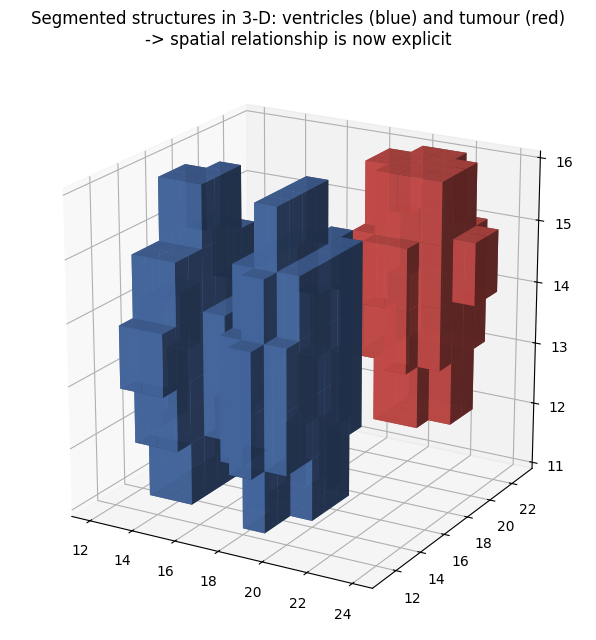

In [18]:
# Segmentation -> 3-D: show the labelled structures as voxels (half resolution to keep it light)
small = seg[::2, ::2, ::2]
fig = plt.figure(figsize=(8, 6.5)); ax = fig.add_subplot(projection="3d")
filled = np.isin(small, [4, 5]).transpose(2, 1, 0)                     # ax.voxels expects (x, y, z)
colors = np.empty(filled.shape, dtype=object)
colors[(small == 4).transpose(2, 1, 0)] = "#4C72B0"; colors[(small == 5).transpose(2, 1, 0)] = "#D9534F"
ax.voxels(filled, facecolors=colors, edgecolor="none", alpha=0.9)
ax.set_box_aspect((NX * 3, NY * 3, NZ * 4)); ax.view_init(20, -60)
ax.set_title("Segmented structures in 3-D: ventricles (blue) and tumour (red)\n-> spatial relationship is now explicit")
plt.tight_layout(); plt.show()

## 17. Simulation Data Visualization: A 3-D Thermal Simulation  *(Slides 33–35)*

**What:** Simulations produce scalar (temperature, pressure), vector (velocity) and tensor (stress) fields that vary
in space and time. Typical pipeline: *Simulation → spatial field → derived variables → visual encoding → analysis*,
using colour maps, contours/isosurfaces, glyphs, streamlines, volume rendering and animation.

**Why:** Below, a small **engineering thermal simulation**: a hot chip (100 °C) sits at the bottom centre of a
40 × 40 × 20 mm aluminium-like block whose outer faces are held at 20 °C. We solve 3-D heat diffusion, then
visualize it with three techniques from this lecture: a slice through time (small multiples = static animation),
isotherm contours, and a derived quantity (volume above 50 °C over time).

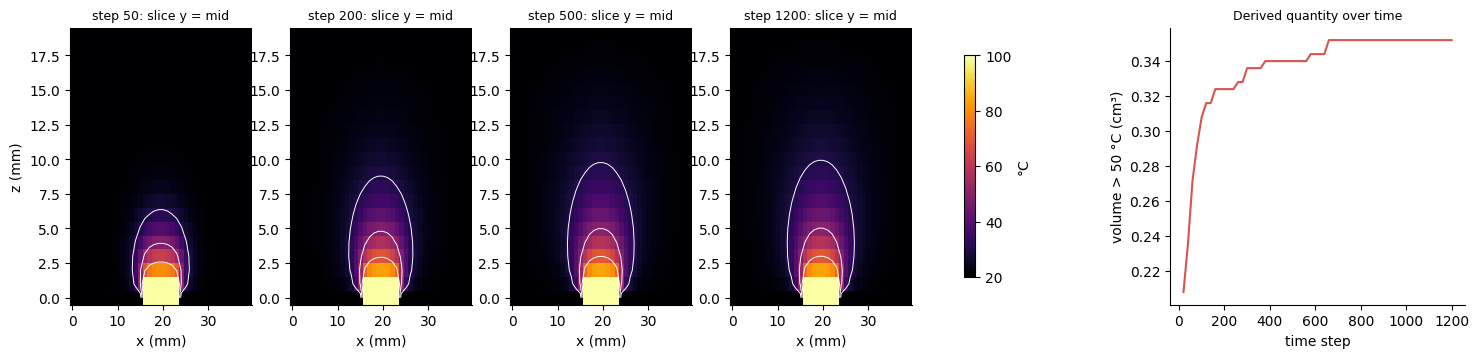

In [19]:
nz_, ny_, nx_ = 20, 40, 40
Tsim = np.full((nz_, ny_, nx_), 20.0)
chip = (slice(0, 2), slice(16, 24), slice(16, 24))
alpha_dt = 0.15                                            # alpha*dt/dx^2 (stable for explicit 3-D scheme: < 1/6)
snapshots, hot_volume, times = {}, [], []
for step in range(1, 1201):
    Tsim[chip] = 100.0
    lap = (-6 * Tsim + np.roll(Tsim, 1, 0) + np.roll(Tsim, -1, 0) + np.roll(Tsim, 1, 1) + np.roll(Tsim, -1, 1)
           + np.roll(Tsim, 1, 2) + np.roll(Tsim, -1, 2))
    Tsim = Tsim + alpha_dt * lap
    Tsim[[0, -1], :, :] = 20; Tsim[:, [0, -1], :] = 20; Tsim[:, :, [0, -1]] = 20; Tsim[chip] = 100.0
    if step % 20 == 0:
        times.append(step); hot_volume.append((Tsim > 50).sum())
    if step in (50, 200, 500, 1200):
        snapshots[step] = Tsim.copy()

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.3]})
for ax, (step, Ts) in zip(axes, snapshots.items()):
    im = ax.imshow(Ts[:, ny_ // 2, :], origin="lower", cmap="inferno", vmin=20, vmax=100, aspect="auto")
    ax.contour(Ts[:, ny_ // 2, :], levels=[30, 50, 70], colors="white", linewidths=0.7)
    ax.set_title(f"step {step}: slice y = mid", fontsize=9); ax.set_xlabel("x (mm)")
axes[0].set_ylabel("z (mm)")
axes[4].plot(times, np.array(hot_volume) / 1000, color="#D9534F"); axes[4].set_xlabel("time step")
axes[4].set_ylabel("volume > 50 °C (cm³)"); axes[4].set_title("Derived quantity over time", fontsize=9)
plt.colorbar(im, ax=axes[:4], shrink=0.8, label="°C")
plt.show()

## Summary: Technique -> When to Use It

| Technique | Solves | Use it when... |
|---|---|---|
| Correct voxel spacing / aspect | Distorted anatomy and wrong measurements | Always — any display or measurement of anisotropic voxels |
| Slicing / slice stack | Occlusion inside a volume | Detailed inspection of internal values; cheap and exact |
| MPR (axial / coronal / sagittal / oblique) | One plane hides 3-D context | Locating a structure across planes; non-axis-aligned anatomy |
| Window / level | 3,000 HU range vs. ~256 grey levels | Every CT slice display (brain vs. bone vs. lung windows) |
| Isosurface (e.g. Marching Cubes) | Need the explicit shape of one level | Bone, organ or material boundaries; 3-D printing; measurement |
| Threshold-sensitivity check | Isosurface geometry depends on c | Before reporting any volume/size derived from a threshold |
| Direct volume rendering (ray casting) | Several structures, no single threshold | Semi-transparent overviews of internal structure |
| Transfer function design | Which values are visible and how | Every DVR — assign colour (identity) and opacity (visibility) distinct roles |
| Front-to-back compositing + early termination | Rendering cost | Interactive volume rendering of large volumes |
| Segmentation + overlays / surfaces | Overlapping intensities, need for numbers | Surgical planning, volumetry, targeted 3-D views |
| Small multiples over time + derived quantities | Simulations evolve in time | Thermal, CFD and weather simulation analysis |

**Core principle:** a volume can never be shown "all at once" — every volume visualization is a choice of *which
structure to reveal* (slice, threshold, transfer function, segment), and that choice should be explicit and
checked.